# Task 1 y Task 2 — Competencia entre dos plataformas

Se estudia el modelo de competencia entre dos plataformas digitales:

$$\dot{x} = r_1 x (1 - x - \alpha_{12} y), \qquad \dot{y} = r_2 y (1 - y - \alpha_{21} x)$$

- $x(t)$ y $y(t)$: base de usuarios de las plataformas A y B (como fracción de su capacidad de mercado).
- $r_1, r_2$: tasas de crecimiento.
- $\alpha_{12}$: cuánto frena B a A. $\alpha_{21}$: cuánto frena A a B.

**Grupo 10** → conjunto 2: $\alpha_{12} = 1.4$, $\alpha_{21} = 1.5$, $r_1 = 1$, $r_2 = 0.9$.

Las funciones del modelo (campo, jacobiana, equilibrios, clasificación) se encuentran en `competencia.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from competencia import campo, clasificar, equilibrios, jacobiana

A12, A21, R1, R2 = 1.4, 1.5, 1.0, 0.9
PARAMS = (A12, A21, R1, R2)
SEMILLA = 42
rng = np.random.default_rng(SEMILLA)

ESTADOS = {"P1": (0.05, 0.05), "P2": (0.80, 0.30), "P3": (0.30, 0.80), "P4": (0.60, 0.60)}

## Task 1.2. Clasificación de los equilibrios

Para cada equilibrio se evalúa la jacobiana $J$ y se calculan la traza $\tau$, el determinante $\Delta$, el discriminante $\tau^2 - 4\Delta$ y los valores propios $\lambda$. Esta tabla solo verifica los cálculos hechos a mano en el documento.

In [2]:
eq = equilibrios(A12, A21)
clase = {}
for nombre, p in eq.items():
    clase[nombre] = clasificar(jacobiana(p, *PARAMS))
    c = clase[nombre]
    print(f"{nombre:>9} ({p[0]:.4f}, {p[1]:.4f}) | τ = {c['τ']:+.4f} | Δ = {c['Δ']:+.4f} | "
          f"τ²-4Δ = {c['τ²-4Δ']:+.4f} | λ = {np.round(c['λ'].real, 4)} | {c['tipo']}")

    (0,0) (0.0000, 0.0000) | τ = +1.9000 | Δ = +0.9000 | τ²-4Δ = +0.0100 | λ = [1.  0.9] | nodo inestable
    (1,0) (1.0000, 0.0000) | τ = -1.4500 | Δ = +0.4500 | τ²-4Δ = +0.3025 | λ = [-1.   -0.45] | nodo estable
    (0,1) (0.0000, 1.0000) | τ = -1.3000 | Δ = +0.3600 | τ²-4Δ = +0.2500 | λ = [-0.9 -0.4] | nodo estable
 interior (0.3636, 0.4545) | τ = -0.7727 | Δ = -0.1636 | τ²-4Δ = +1.2517 | λ = [ 0.173  -0.9458] | silla


### Plano traza-determinante

Debajo de la parábola $\tau^2 = 4\Delta$ se ubican los nodos y encima los focos. Con $\Delta < 0$ el equilibrio es una silla; con $\Delta > 0$, el signo de $\tau$ indica si es estable ($\tau < 0$) o inestable ($\tau > 0$).

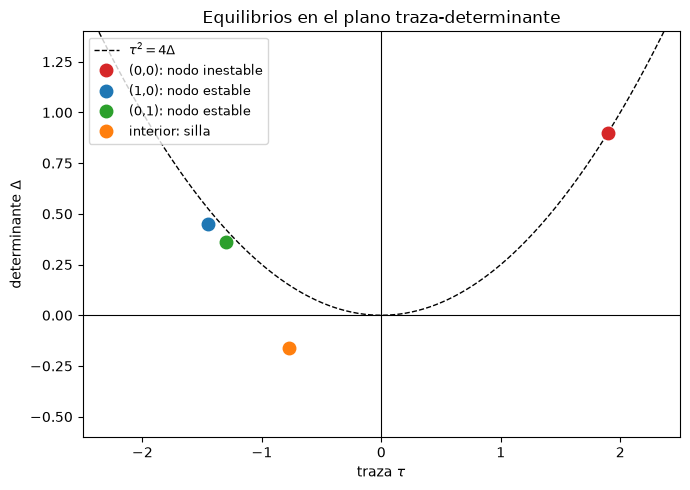

In [3]:
COLORES = {"(0,0)": "tab:red", "(1,0)": "tab:blue", "(0,1)": "tab:green", "interior": "tab:orange"}

fig, ax = plt.subplots(figsize=(7, 5))
t = np.linspace(-2.5, 2.5, 400)
ax.plot(t, t**2 / 4, "k--", lw=1, label=r"$\tau^2 = 4\Delta$")
ax.axhline(0, color="k", lw=0.8)
ax.axvline(0, color="k", lw=0.8)
for nombre, c in clase.items():
    ax.plot(c["τ"], c["Δ"], "o", ms=9, color=COLORES[nombre], label=f"{nombre}: {c['tipo']}")
ax.set_xlim(-2.5, 2.5)
ax.set_ylim(-0.6, 1.4)
ax.set_xlabel(r"traza $\tau$")
ax.set_ylabel(r"determinante $\Delta$")
ax.set_title("Equilibrios en el plano traza-determinante")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig("figuras/traza_determinante.png", dpi=150)
plt.show()

## Task 1.3. Nulclinas y dirección del campo

Las **nulclinas** son las curvas donde una de las derivadas vale cero:

- Nulclinas de $x$ ($\dot{x} = 0$): $x = 0$ y $x + 1.4y = 1$.
- Nulclinas de $y$ ($\dot{y} = 0$): $y = 0$ y $y + 1.5x = 1$.

Sus intersecciones son los equilibrios. En cada región se dibuja una flecha según los signos de $\dot{x}$ y $\dot{y}$.

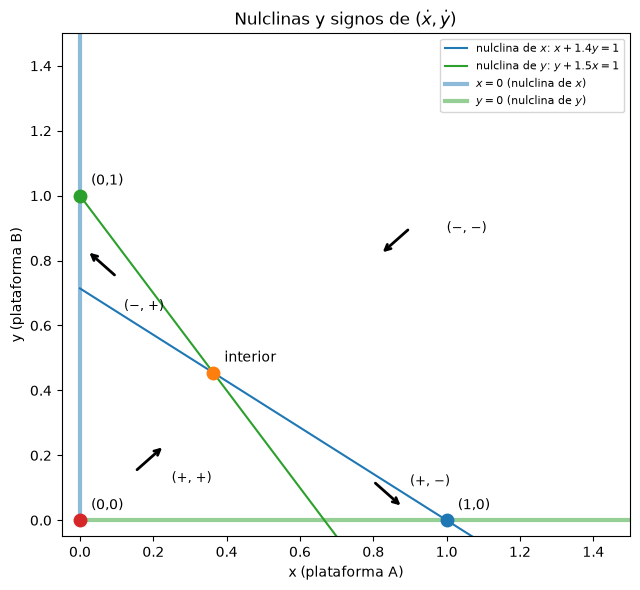

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 6))
xs = np.linspace(0, 1.5, 200)
ax.plot(xs, (1 - xs) / A12, color="tab:blue", label=r"nulclina de $x$: $x + 1.4y = 1$")
ax.plot(xs, 1 - A21 * xs, color="tab:green", label=r"nulclina de $y$: $y + 1.5x = 1$")
ax.plot([0, 0], [0, 1.5], color="tab:blue", lw=3, alpha=0.5, label=r"$x = 0$ (nulclina de $x$)")
ax.plot([0, 1.5], [0, 0], color="tab:green", lw=3, alpha=0.5, label=r"$y = 0$ (nulclina de $y$)")

for nombre, p in eq.items():
    ax.plot(*p, "o", ms=9, color=COLORES[nombre], zorder=5)
    ax.annotate(nombre, p, textcoords="offset points", xytext=(8, 8))

# Una flecha por región, con la dirección dada por los signos de (dx/dt, dy/dt)
REGIONES = [((0.15, 0.15), (0.25, 0.13)), ((0.9, 0.9), (1.0, 0.9)),
            ((0.8, 0.12), (0.9, 0.12)), ((0.1, 0.75), (0.12, 0.66))]
for p, pos_texto in REGIONES:
    dx, dy = np.sign(campo(p, *PARAMS))
    ax.annotate("", xy=(p[0] + 0.08 * dx, p[1] + 0.08 * dy), xytext=p,
                arrowprops=dict(arrowstyle="->", lw=2, color="k"))
    ax.text(*pos_texto, f"({'+' if dx > 0 else '−'}, {'+' if dy > 0 else '−'})", va="center", fontsize=9)

ax.set_xlim(-0.05, 1.5)
ax.set_ylim(-0.05, 1.5)
ax.set_xlabel("x (plataforma A)")
ax.set_ylabel("y (plataforma B)")
ax.set_title(r"Nulclinas y signos de $(\dot{x}, \dot{y})$")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig("figuras/nulclinas.png", dpi=150)
plt.show()